# Padel Markov Model
This is a project that uses Markov chains to find the probability of winning a padel match based on independent, single-point winning probability. It then uses Monte Carlo simulation to simulate a large number of padel matches to check that the probabilities calculated before are correct. This allows me to explore what effect the deuce rule (golden point, advantage, or star point) has on the outcome of a match.

In [1]:
from padel import *
from simulate import *
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(4)

In [2]:
def check(sim_fn, exact, n=20_000):
    """Run sim_fn n times, compare the win rate with the exact answer."""
    wins = sum(sim_fn() for _ in range(n))
    est = wins / n
    se = (est * (1 - est) / n) ** 0.5
    ok = abs(est - exact) < 2 * se
    print(f"Sim: {est:.4f}   Exact: {exact:.4f}   SE: {se:.4f}   {'OK' if ok else 'CHECK'}")

The exact Markov model and the independent simulators are compared below across all three deuce rules to check the accuracy of all models.

In [ ]:
rules = [("Golden",    sim_game_golden, hold_golden),
("Advantage", sim_game_advantage,  hold_advantage),
("Star",      sim_game_star,   hold_star),
]

for name, sim_game, hold in rules:
    for p_a, p_b in [(0.6, 0.6), (0.62, 0.58), (0.7, 0.55)]:
        print(f"{name}, {p_a}, {p_b}:   ")
        check(lambda: sim_match(p_a, p_b, sim_game), match_prob(p_a, p_b, hold))
        print()

Golden, 0.6, 0.6:   
Sim: 0.4978   Exact: 0.5000   SE: 0.0035   OK

Golden, 0.62, 0.58:   
Sim: 0.6818   Exact: 0.6805   SE: 0.0033   OK

Golden, 0.7, 0.55:   
Sim: 0.9580   Exact: 0.9592   SE: 0.0014   OK

Advantage, 0.6, 0.6:   
Sim: 0.4985   Exact: 0.5000   SE: 0.0035   OK

Advantage, 0.62, 0.58:   
Sim: 0.6915   Exact: 0.6974   SE: 0.0033   OK

Advantage, 0.7, 0.55:   
Sim: 0.9686   Exact: 0.9705   SE: 0.0012   OK

Star, 0.6, 0.6:   
Sim: 0.5010   Exact: 0.5000   SE: 0.0035   OK

Star, 0.62, 0.58:   
Sim: 0.6945   Exact: 0.6942   SE: 0.0033   OK

Star, 0.7, 0.55:   
Sim: 0.9685   Exact: 0.9689   SE: 0.0012   OK



Below are some common-sense checks.
- I check that if both teams win the same share of points on serve, each should then win 50% of matches.
- I also check that the order of the server doesn't affect the outcome of a match.
- The third checks that if a team wins every point they win every match.


In [4]:
check(lambda: sim_match(0.6, 0.6), 0.5)                       # equal teams: 50/50
check(lambda: sim_match(0.62, 0.58, server="B"),
      match_prob(0.62, 0.58))                                 # B serving first: same answer
print(sim_match(1.0, 0.0))

Sim: 0.4989   Exact: 0.5000   SE: 0.0035   OK
Sim: 0.6957   Exact: 0.6942   SE: 0.0033   OK
True


## Result 1: The deuce rule and holding serve

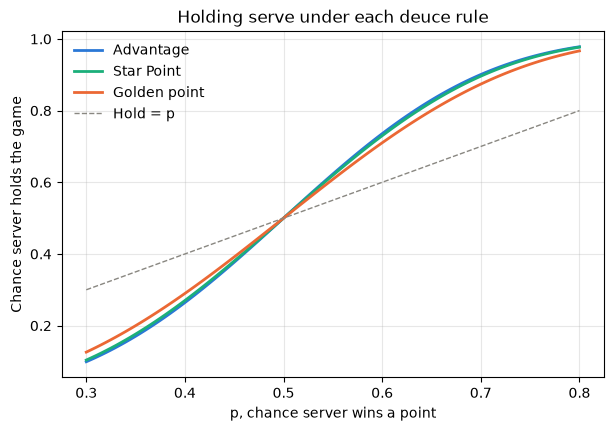

In [ ]:
ps = np.linspace(0.3, 0.8, 101)

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.plot(ps, [hold_advantage(p) for p in ps], color="#2a78d6", lw=2, label="Advantage")
ax.plot(ps, [hold_star(p) for p in ps], color="#1baf7a", lw=2, label="Star Point")
ax.plot(ps, [hold_golden(p) for p in ps], color="#eb6834", lw=2, label="Golden point")
ax.plot(ps, ps, color="#898781", lw=1, ls="--", label="Hold = p")

ax.set_xlabel("p, chance server wins a point")
ax.set_ylabel("Chance server holds the game")
ax.set_title("Holding serve under each deuce rule")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()

- As visible in the graph, at p = 0.5, the type of game doesn't matter and the chance that the server holds the game is always 0.5.
- As the better player with a higher probability of winning a point, it is best for you to play with advantage rules. This is due to a higher number of points being played.
- As the worse player with a lower probability of winning a point, it is best to play with golden point rules. This is due to less points being played.

## Result 2: Small edges per point become big edges per match

In [6]:
p_a, p_b = 0.62, 0.58

point = (p_a + (1 - p_b)) / 2
game = (hold_star(p_a) + (1 - hold_star(p_b))) / 2

print(f"Point (avg): {point:.3f}")
print(f"Game (avg):  {game:.3f}")
print(f"Set:         {set_prob(p_a, p_b):.3f}")
print(f"Match:       {match_prob(p_a, p_b):.3f}")

Point (avg): 0.520
Game (avg):  0.541
Set:         0.633
Match:       0.694


You can see from this that A's edge grows as more of the match is played. This is due to more points being played which lessens the effect of luck. \
The jump from point to game is smaller than game to set. This is due to whoever is serving winning more games regardless of which team is better. The serving advantage cancels out across the set as each team serves equally often. 

## Result 3: Does the deuce rule change who wins the match?

In [ ]:
for name, hold in [("Golden", hold_golden), ("Star", hold_star), ("Advantage", hold_advantage)]:
    print(f"{name:10} {match_prob(0.62, 0.58, hold):.4f}")

p = 0.6
print(f"Probability of game becoming 40-40: {20 * p**3 * (1 - p)**3:.4f}")

Golden     0.6805
Star       0.6942
Advantage  0.6974
Probability of game becoming 40-40: 0.2765


From this, you can see that the deuce rule makes very little difference to who wins the match. The chance of winning only changes by about 1.7 percentage points between advantage and golden point, which is less than 2 matches per 100. This is because the rule only matters once a game reaches 40-40, which only happens in about 28% of service games at p = 0.6. Star Point is almost identical to advantage (0.694 vs 0.697). The main purpose of the change from advantage to Star Point is therefore likely to just be to shorten matches while barely changing the outcome of the match.